# Лабораторная работа 1
## Сравнение `mean_pooling` и `cls_pooling`

### Задание

1. Выбрать датасет для задачи классификации текстов https://huggingface.co/datasets
2. Выбрать модель векторизации https://huggingface.co/models
3. Обучить классификатор с `mean_pooling`.
4. Посчитать метрики: `F1-Score`, `Precision`, `Recall`.
5. Обучить классификатор с `cls_pooling`.
6. Посчитать метрики: `F1-Score`, `Precision`, `Recall`.
7. Сравнить метрики, полученные при использовании разных стратегий пулинга.

### Выбранные данные

- Датасет: `google-research-datasets/paws`
- Конфигурация датасета: `labeled_final`
- Модель: `google/embeddinggemma-300m`

PAWS содержит **пары предложений**.  
`label = 1` означает, что предложения являются перефразировками друг друга, 
`label = 0` что смысл у предложений различается

В работе будем подавать два предложения модели как один текст, а затем сравним два способа получить один вектор из последовательности токенов

#### Импорт

In [22]:
import gc
import random
from collections import Counter
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from huggingface_hub import get_token
from sklearn.metrics import (
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm
from transformers import AutoModel, AutoTokenizer


print("PyTorch:", torch.__version__)
print("Datasets:", datasets.__version__)

PyTorch: 2.7.1+cu126
Datasets: 4.8.5


In [23]:
def set_random_state(random_state:int=0):
    """Initialize random generators.

    Parameters
    ==========
    random_state : int = 0
        Determines random number generation for centroid initialization.
        Use an int to make the randomness deterministic.
    """
    torch.manual_seed(random_state)
    random.seed(random_state)
    np.random.seed(random_state)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(random_state)
        torch.cuda.manual_seed(random_state)

        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

SEED = 42
set_random_state(SEED)
#torch.use_deterministic_algorithms(True)
torch.use_deterministic_algorithms(False)

%env CUBLAS_WORKSPACE_CONFIG=:4096:8
%env PYTHONHASHSEED=42

env: CUBLAS_WORKSPACE_CONFIG=:4096:8
env: PYTHONHASHSEED=42


### Data preprocessing

Зададим основные параметры в одном месте

`FAST_MODE = False` означает работу со всем датасетом

In [ ]:
DATASET_NAME = "google-research-datasets/paws"
DATASET_CONFIG = "labeled_final"
MODEL_NAME = "google/embeddinggemma-300m"

DATA_DIR = Path("data")
MODEL_DIR = Path("models") / "embeddinggemma-300m"
HF_CACHE_DIR = Path("hf_cache")
PAWS_DIR = DATA_DIR / "paws_labeled_final"

DATA_DIR.mkdir(exist_ok=True)
MODEL_DIR.parent.mkdir(exist_ok=True)
HF_CACHE_DIR.mkdir(exist_ok=True)

MAX_LENGTH = 128
BATCH_SIZE = 16
NUM_EPOCHS = 3
LEARNING_RATE = 1e-3

# True - обучаем только классификатор
FREEZE_ENCODER = True

# False - используем весь датасет
FAST_MODE = False

FAST_TRAIN_SIZE = 5000
FAST_VAL_SIZE = 1000
FAST_TEST_SIZE = 1000

#### Загрузка датасета

Сначала проверяем, сохранён ли PAWS в папке `data/paws_labeled_final`

Таким образом, при следующих запусках повторно скачивать датасет не нужно

In [26]:
if (PAWS_DIR / "dataset_dict.json").exists():
    print("Датасет найден локально. Загружаем с диска.")
    ds = datasets.load_from_disk(PAWS_DIR)
else:
    print("Локальной копии нет. Скачиваем датасет с Hugging Face.")
    ds = datasets.load_dataset(
        DATASET_NAME,
        DATASET_CONFIG,
        cache_dir=HF_CACHE_DIR,
    )
    ds.save_to_disk(PAWS_DIR)
    print("Датасет сохранён в:", PAWS_DIR.resolve())


if FAST_MODE:
    print("\nFAST_MODE включён: берём небольшую часть данных.")

    ds["train"] = (
        ds["train"]
        .shuffle(seed=SEED)
        .select(range(min(FAST_TRAIN_SIZE, len(ds["train"]))))
    )

    ds["validation"] = (
        ds["validation"]
        .shuffle(seed=SEED)
        .select(range(min(FAST_VAL_SIZE, len(ds["validation"]))))
    )

    ds["test"] = (
        ds["test"]
        .shuffle(seed=SEED)
        .select(range(min(FAST_TEST_SIZE, len(ds["test"]))))
    )

Датасет найден локально. Загружаем с диска.


In [27]:
ds

DatasetDict({
    train: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 49401
    })
    test: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 8000
    })
    validation: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 8000
    })
})

Посмотрим, сколько примеров каждого класса есть в обучающей выборке.

In [28]:
Counter(ds["train"]["label"])

Counter({0: 27572, 1: 21829})

In [29]:
id2label = {
    0: "not paraphrase",
    1: "paraphrase",
}

class_labels = [id2label[i] for i in sorted(id2label)]

id2label

{0: 'not paraphrase', 1: 'paraphrase'}

Посмотрим на длину пар предложений. Здесь считаем количество символов в двух предложениях вместе

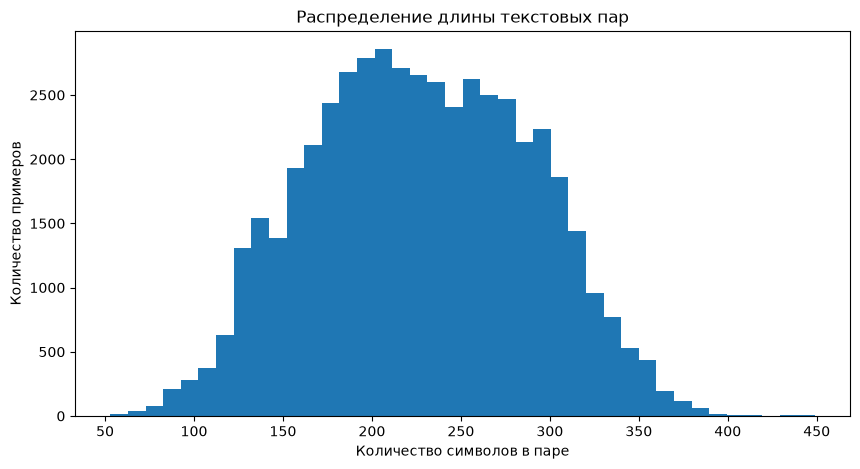

In [30]:
text_lengths = [
    len(sentence1) + len(sentence2)
    for sentence1, sentence2 in zip(
        ds["train"]["sentence1"],
        ds["train"]["sentence2"],
    )
]

plt.figure(figsize=(10, 5))
plt.hist(text_lengths, bins=40)
plt.xlabel("Количество символов в паре")
plt.ylabel("Количество примеров")
plt.title("Распределение длины текстовых пар")
plt.show()

Выведем первые примеры датасета.

In [31]:
pd.set_option("display.max_colwidth", None)

pd.DataFrame.from_dict(ds["train"][:10])

,id,sentence1,sentence2,label
0,1,"In Paris , in October 1560 , he secretly met the English ambassador , Nicolas Throckmorton , asking him for a passport to return to England through Scotland .","In October 1560 , he secretly met with the English ambassador , Nicolas Throckmorton , in Paris , and asked him for a passport to return to Scotland through England .",0
1,2,The NBA season of 1975 -- 76 was the 30th season of the National Basketball Association .,The 1975 -- 76 season of the National Basketball Association was the 30th season of the NBA .,1
2,3,"There are also specific discussions , public profile debates and project discussions .","There are also public discussions , profile specific discussions , and project discussions .",0
3,4,"When comparable rates of flow can be maintained , the results are high .",The results are high when comparable flow rates can be maintained .,1
4,5,It is the seat of Zerendi District in Akmola Region .,It is the seat of the district of Zerendi in Akmola region .,1
5,6,"William Henry Henry Harman was born on 17 February 1828 in Waynesboro , Virginia , where his parents were Lewis and Sally ( Garber ) Harman .","William Henry Harman was born in Waynesboro , Virginia on February 17 , 1828 . His parents were Lewis and Sally ( Garber ) Harman .",1
6,7,"Bullion Express - concept is being introduced new store in Dallas , Texas in Preston Center opened .","2011-DGSE Bullion Express concept is introduced , new store opened in Preston Center in Dallas , Texas",0
7,8,"With a discrete amount of probabilities Formula 1 with the condition formula 2 and Formula 3 any real number , the Tsallis is defined as entropy as","Given a discrete set of probabilities formula _ 1 with the condition formula _ 2 , and formula _ 3 any real number , the Tsallis entropy is defined as",1
8,9,"The Soviet Union maintained an embassy in Oslo and a consulate in Barentsburg , while Norway maintained a message in Moscow .","The Soviet Union maintained an embassy in Moscow and a consulate in Barentsburg , while Norway maintained a message in Oslo .",0
9,10,Vocabulary even went to Brazil through leaving Portuguese settlers with some Macanese and Chinese settlers .,Vocabulary even went to Brazil by leaving Macanese and Chinese settlers with some Portuguese settlers .,0


### Tokenization

В PAWS один объект состоит из **двух предложений**, поэтому объединим их в одну строку понятного вида:

`task: classification | query: sentence 1: ... | sentence 2: ...`

Для `cls_pooling` важно, чтобы первый токен действительно находился в начале текста. Поэтому ставим `padding_side = "right"`

Модель будет загружена через `AutoModel`, а pooling реализую. Это нужно для честного сравнения `mean_pooling` и `cls_pooling`

In [ ]:
def model_saved_locally(model_dir: Path):
    config_exists = (model_dir / "config.json").exists()

    weights_exist = any(
        (model_dir / name).exists()
        for name in [
            "model.safetensors",
            "model.safetensors.index.json",
            "pytorch_model.bin",
            "pytorch_model.bin.index.json",
        ]
    )

    return config_exists and weights_exist

MODEL_IS_LOCAL = model_saved_locally(MODEL_DIR)

if MODEL_IS_LOCAL:
    print("Модель уже сохранена локально:", MODEL_DIR.resolve())
    tokenizer_source = str(MODEL_DIR)
else:
    print("Локальной модели пока нет.")

    if get_token() is None:
        raise RuntimeError("Для google/embeddinggemma-300m нужно принять лицензию модели")

    tokenizer_source = MODEL_NAME


tokenizer = AutoTokenizer.from_pretrained(
    tokenizer_source,
    cache_dir=HF_CACHE_DIR,
    local_files_only=MODEL_IS_LOCAL,
)

# Для cls_pooling первый элемент должен быть начальным токеном, а не padding-токеном
tokenizer.padding_side = "right"

print("padding_side:", tokenizer.padding_side)
print("bos_token:", tokenizer.bos_token)
print("pad_token:", tokenizer.pad_token)

Модель уже сохранена локально: D:\МАГА\2 курс\Разговорный ИИ\сам\models\embeddinggemma-300m
padding_side: right
bos_token: <bos>
pad_token: <pad>


In [33]:
def prepare_texts(data):
    texts = []

    for sentence1, sentence2 in zip(
        data["sentence1"],
        data["sentence2"],
    ):
        text = (
            "task: classification | query: "
            f"sentence 1: {sentence1} | "
            f"sentence 2: {sentence2}"
        )
        texts.append(text)

    return texts


def tokenize_data(data, max_length=MAX_LENGTH):
    texts = prepare_texts(data)

    tokens = tokenizer(
        texts,
        max_length=max_length,
        padding="max_length",
        truncation=True,
        return_tensors="pt",
    )

    return tokens


train_tokens = tokenize_data(ds["train"])
val_tokens = tokenize_data(ds["validation"])
test_tokens = tokenize_data(ds["test"])

In [34]:
print("Train:", train_tokens["input_ids"].shape)
print("Validation:", val_tokens["input_ids"].shape)
print("Test:", test_tokens["input_ids"].shape)

Train: torch.Size([49401, 128])
Validation: torch.Size([8000, 128])
Test: torch.Size([8000, 128])


In [35]:
train_dataset = TensorDataset(
    train_tokens["input_ids"],
    train_tokens["attention_mask"],
    torch.tensor(ds["train"]["label"], dtype=torch.long),
)

val_dataset = TensorDataset(
    val_tokens["input_ids"],
    val_tokens["attention_mask"],
    torch.tensor(ds["validation"]["label"], dtype=torch.long),
)

test_dataset = TensorDataset(
    test_tokens["input_ids"],
    test_tokens["attention_mask"],
    torch.tensor(ds["test"]["label"], dtype=torch.long),
)

In [ ]:
def make_loaders():
    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    return train_loader, val_loader, test_loader

### Loading Pretrained

In [37]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)

Device: cuda


In [38]:
def load_pretrained_model():
    local_model_exists = model_saved_locally(MODEL_DIR)

    if local_model_exists:
        print("Используем локальную модель.")
        source = str(MODEL_DIR)
    else:
        print("Скачиваем модель с Hugging Face.")
        source = MODEL_NAME

    pretrained = AutoModel.from_pretrained(
        source,
        cache_dir=HF_CACHE_DIR,
        local_files_only=local_model_exists,
        dtype=torch.float32,
    )
    
    # После первого скачивания сохраняем отдельную локальную копию.
    if not local_model_exists:
        MODEL_DIR.mkdir(parents=True, exist_ok=True)
        pretrained.save_pretrained(MODEL_DIR)
        tokenizer.save_pretrained(MODEL_DIR)
        print("Модель сохранена в:", MODEL_DIR.resolve())

    return pretrained

### Обучение

Общая структура: модель-векторизатор, pooling и один линейный слой-классификатор

По умолчанию веса EmbeddingGemma **заморожены**, поэтому обучается только последний классификатор

In [39]:
def train_or_validate(
    model,
    loader,
    epoch,
    num_epochs,
    optimizer,
    mode,
):
    total_loss = 0

    for input_ids, attention_mask, labels in tqdm(
        loader,
        desc=f"{mode} epoch {epoch + 1}/{num_epochs}",
    ):
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        if mode == "Training":
            optimizer.zero_grad(set_to_none=True)

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )

        loss = F.cross_entropy(logits, labels)
        total_loss += loss.item()

        if mode == "Training":
            loss.backward()
            optimizer.step()

    average_loss = total_loss / len(loader)

    print(
        f"{mode} epoch {epoch + 1}/{num_epochs}: "
        f"loss = {average_loss:.4f}"
    )


def train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    num_epochs=NUM_EPOCHS,
):
    for epoch in range(num_epochs):
        model.train()

        train_or_validate(
            model,
            train_loader,
            epoch,
            num_epochs,
            optimizer,
            mode="Training",
        )

        model.eval()

        with torch.inference_mode():
            train_or_validate(
                model,
                val_loader,
                epoch,
                num_epochs,
                optimizer,
                mode="Validation",
            )

In [ ]:
class Classifier(torch.nn.Module):
    def __init__(
        self,
        pretrained,
        pooling_type,
        num_classes=2,
        freeze_encoder=True,
    ):
        super().__init__()

        self.pooling_type = pooling_type
        self.pretrained = pretrained
        self.freeze_encoder = freeze_encoder

        if self.freeze_encoder:
            for parameter in self.pretrained.parameters():
                parameter.requires_grad = False

        hidden_size = self.pretrained.config.hidden_size
        self.classifier = torch.nn.Linear(hidden_size, num_classes)

    def mean_pooling(
        self,
        token_embeddings,
        attention_mask,
    ):
        input_mask_expanded = (
            attention_mask
            .unsqueeze(-1)
            .expand(token_embeddings.shape)
            .float()
        )

        sum_embeddings = torch.sum(
            token_embeddings * input_mask_expanded,
            dim=1,
        )

        sum_mask = torch.clamp(
            input_mask_expanded.sum(dim=1),
            min=1e-9,
        )

        return sum_embeddings / sum_mask

    def cls_pooling(
        self,
        token_embeddings,
        attention_mask,
    ):
        # В Gemma это первый <bos>-токен
        return token_embeddings[:, 0]

    def forward(self, input_ids, attention_mask):
        if self.freeze_encoder:
            # Векторизатор не обучаем
            self.pretrained.eval()

            with torch.no_grad():
                outputs = self.pretrained(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                )
        else:
            outputs = self.pretrained(
                input_ids=input_ids,
                attention_mask=attention_mask,
            )

        if self.pooling_type == "mean":
            embeddings = self.mean_pooling(
                outputs.last_hidden_state,
                attention_mask,
            )
        elif self.pooling_type == "cls":
            embeddings = self.cls_pooling(
                outputs.last_hidden_state,
                attention_mask,
            )
        else:
            raise ValueError("pooling_type должен быть 'mean' или 'cls'")

        logits = self.classifier(embeddings)

        return logits

In [41]:
def evaluate_model(model, loader):
    preds = []
    labels = []

    model.eval()

    with torch.inference_mode():
        for input_ids, attention_mask, batch_labels in tqdm(
            loader,
            desc="Evaluation",
        ):
            logits = model(
                input_ids=input_ids.to(device),
                attention_mask=attention_mask.to(device),
            )

            batch_preds = torch.argmax(
                logits,
                dim=1,
            ).cpu().tolist()

            preds.extend(batch_preds)
            labels.extend(batch_labels.tolist())

    return preds, labels


def clear_memory():
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## Mean pooling

`mean_pooling` усредняет векторы всех настоящих токенов текста. Padding-токены в среднее не входят благодаря `attention_mask`.

In [42]:
torch.manual_seed(SEED)

train_loader, val_loader, test_loader = make_loaders()

pretrained_mean = load_pretrained_model()

classifier_mean = Classifier(
    pretrained_mean,
    pooling_type="mean",
    num_classes=2,
    freeze_encoder=FREEZE_ENCODER,
).to(device)

optimizer_mean = torch.optim.AdamW(
    filter(
        lambda parameter: parameter.requires_grad,
        classifier_mean.parameters(),
    ),
    lr=LEARNING_RATE,
)

train_model(
    classifier_mean,
    train_loader,
    val_loader,
    optimizer_mean,
)

Используем локальную модель.


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Training epoch 1/3:   0%|          | 0/3088 [00:00<?, ?it/s]

Training epoch 1/3: loss = 0.6938


Validation epoch 1/3:   0%|          | 0/500 [00:00<?, ?it/s]

...

Validation epoch 2/3: loss = 0.6686


Training epoch 3/3:   0%|          | 0/3088 [00:00<?, ?it/s]

Training epoch 3/3: loss = 0.6851


Validation epoch 3/3:   0%|          | 0/500 [00:00<?, ?it/s]

Validation epoch 3/3: loss = 0.6786


In [44]:
preds_mean, labels_mean = evaluate_model(
    classifier_mean,
    test_loader,
)

print(
    classification_report(
        labels_mean,
        preds_mean,
        target_names=class_labels,
        digits=4,
        zero_division=0,
    )
)

Evaluation:   0%|          | 0/500 [00:00<?, ?it/s]

                precision    recall  f1-score   support

not paraphrase     0.6228    0.5663    0.5932      4464
    paraphrase     0.5088    0.5670    0.5363      3536

      accuracy                         0.5666      8000
     macro avg     0.5658    0.5667    0.5648      8000
  weighted avg     0.5724    0.5666    0.5681      8000



In [45]:
del classifier_mean
del pretrained_mean
del optimizer_mean

clear_memory()

## CLS pooling

В BERT обычно используется специальный токен `[CLS]`.  
У Gemma такого токена нет, поэтому под `cls_pooling` берём **вектор первого токена**.

При правом padding первым токеном является `<bos>`.

In [46]:
torch.manual_seed(SEED)

train_loader, val_loader, test_loader = make_loaders()

pretrained_cls = load_pretrained_model()

classifier_cls = Classifier(
    pretrained_cls,
    pooling_type="cls",
    num_classes=2,
    freeze_encoder=FREEZE_ENCODER,
).to(device)

optimizer_cls = torch.optim.AdamW(
    filter(
        lambda parameter: parameter.requires_grad,
        classifier_cls.parameters(),
    ),
    lr=LEARNING_RATE,
)

train_model(
    classifier_cls,
    train_loader,
    val_loader,
    optimizer_cls,
)

Используем локальную модель.


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Training epoch 1/3:   0%|          | 0/3088 [00:00<?, ?it/s]

Training epoch 1/3: loss = 0.8188


Validation epoch 1/3:   0%|          | 0/500 [00:00<?, ?it/s]

...

Validation epoch 2/3: loss = 0.6937


Training epoch 3/3:   0%|          | 0/3088 [00:00<?, ?it/s]

Training epoch 3/3: loss = 0.7923


Validation epoch 3/3:   0%|          | 0/500 [00:00<?, ?it/s]

Validation epoch 3/3: loss = 0.7739


In [47]:
preds_cls, labels_cls = evaluate_model(
    classifier_cls,
    test_loader,
)

print(
    classification_report(
        labels_cls,
        preds_cls,
        target_names=class_labels,
        digits=4,
        zero_division=0,
    )
)

Evaluation:   0%|          | 0/500 [00:00<?, ?it/s]

                precision    recall  f1-score   support

not paraphrase     0.5775    0.9191    0.7093      4464
    paraphrase     0.5966    0.1510    0.2410      3536

      accuracy                         0.5796      8000
     macro avg     0.5871    0.5351    0.4752      8000
  weighted avg     0.5860    0.5796    0.5023      8000



In [48]:
del classifier_cls
del pretrained_cls
del optimizer_cls

clear_memory()

## Сравнение метрик

Для итогового сравнения используем `macro`-усреднение

In [49]:
def calculate_metrics(labels, preds):
    return {
        "Precision": precision_score(
            labels,
            preds,
            average="macro",
            zero_division=0,
        ),
        "Recall": recall_score(
            labels,
            preds,
            average="macro",
            zero_division=0,
        ),
        "F1-Score": f1_score(
            labels,
            preds,
            average="macro",
            zero_division=0,
        ),
    }


mean_metrics = calculate_metrics(
    labels_mean,
    preds_mean,
)

cls_metrics = calculate_metrics(
    labels_cls,
    preds_cls,
)

comparison = pd.DataFrame(
    [
        {
            "Pooling": "mean_pooling",
            **mean_metrics,
        },
        {
            "Pooling": "cls_pooling",
            **cls_metrics,
        },
    ]
)

comparison

,Pooling,Precision,Recall,F1-Score
0,mean_pooling,0.565784,0.566667,0.564765
1,cls_pooling,0.587064,0.535074,0.475169


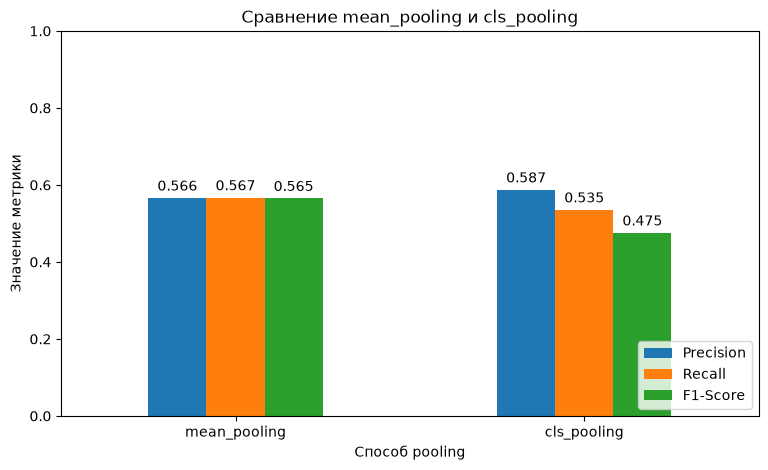

In [50]:
plot_data = comparison.set_index("Pooling")[
    ["Precision", "Recall", "F1-Score"]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0,
)

plt.ylim(0, 1)
plt.ylabel("Значение метрики")
plt.xlabel("Способ pooling")
plt.title("Сравнение mean_pooling и cls_pooling")
plt.legend(loc="lower right")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
    )

plt.show()

### Вывод

Были сравнены два способа получения единого векторного представления текста на основе модели `google/embeddinggemma-300m`: `mean_pooling` и `cls_pooling`. В качестве данных использовался датасет PAWS (`google-research-datasets/paws`, конфигурация `labeled_final`), а энкодер во время обучения был заморожен, поэтому обучался только линейный классификатор

Несмотря на немного более высокий `Precision` у `cls_pooling`, его итоговый `F1-Score` оказался существенно ниже. Разница по macro F1 составляет около **0.090** в пользу `mean_pooling`. Кроме того, при `cls_pooling` наблюдается сильный перекос между классами: для класса `not paraphrase` Recall равен **0.919**, тогда как для класса `paraphrase` - только **0.151**. То есть классификатор значительно чаще относит объекты к классу `not paraphrase`. Поэтому немного более высокая Accuracy у `cls_pooling` (**0.580** против **0.567**) не означает более качественную классификацию обоих классов

При `mean_pooling` значения Recall для двух классов значительно более сбалансированы: **0.566** для `not paraphrase` и **0.567** для `paraphrase`. Усреднение представлений всех непустых токенов в данном эксперименте позволило получить более информативный общий вектор пары предложений, чем использование только представления первого `<bos>`-токена

Таким образом, **для выбранной модели, датасета и схемы обучения `mean_pooling` оказался предпочтительнее `cls_pooling`**, поскольку обеспечивает более высокий macro F1 и более равномерное качество классификации двух классов